<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Cuadernos/03_Sentimiento_Regresion_Logistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Análisis de sentimiento con regresión logística</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Introducción</span>](#introduccion)
- [<span style="color: #005C99;">Datos: tweets etiquetados</span>](#datos-tweets-etiquetados)
- [<span style="color: #005C99;">Preprocesamiento de tweets</span>](#preprocesamiento-de-tweets)
- [<span style="color: #005C99;">Extracción de características</span>](#extraccion-de-caracteristicas)
- [<span style="color: #005C99;">Modelo de regresión logística</span>](#modelo-de-regresion-logistica)
- [<span style="color: #005C99;">Entrenamiento con descenso del gradiente</span>](#entrenamiento-con-descenso-del-gradiente)
- [<span style="color: #005C99;">Evaluación</span>](#evaluacion)
- [<span style="color: #005C99;">Regresión logística con scikit-learn</span>](#regresion-logistica-con-scikit-learn)
- [<span style="color: #005C99;">Análisis de errores</span>](#analisis-de-errores)
- [<span style="color: #005C99;">Referencias</span>](#referencias)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn nltk

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import string
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from nltk.corpus import twitter_samples, stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import TweetTokenizer

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
# Algunos tweets contienen caracteres que la fuente de matplotlib no puede dibujar
warnings.filterwarnings("ignore", message="Glyph")

for recurso in ["twitter_samples", "stopwords"]:
    nltk.download(recurso, quiet=True)

<a id="introduccion"></a>
<h2 style="color: #007ACC;">Introducción</h2>

El **análisis de sentimiento** consiste en determinar la actitud u opinión expresada en un texto: positiva, negativa o neutra. Es una de las aplicaciones más extendidas del PLN: monitoreo de marca en redes sociales, análisis de reseñas de productos, encuestas de satisfacción, atención al cliente...

Lo plantearemos como un problema de **clasificación binaria supervisada**: dado un tweet $x$, predecir $y \in \{0, 1\}$ (negativo / positivo).

En este cuaderno:

1. Preprocesamos tweets con lo visto en el cuaderno 01.
2. Construimos un extractor de características muy simple basado en **frecuencias de palabras por clase**.
3. Implementamos la **regresión logística desde cero** con NumPy, incluyendo el descenso del gradiente.
4. La comparamos con la implementación de `scikit-learn` sobre una representación TF-IDF.
5. Analizamos los errores y descubrimos un problema sutil del conjunto de datos.

<a id="datos-tweets-etiquetados"></a>
<h2 style="color: #007ACC;">Datos: tweets etiquetados</h2>

Usaremos el corpus `twitter_samples` de NLTK: **5 000 tweets positivos y 5 000 negativos** en inglés.

In [3]:
positivos = twitter_samples.strings("positive_tweets.json")
negativos = twitter_samples.strings("negative_tweets.json")

tweets = positivos + negativos
etiquetas = np.array([1] * len(positivos) + [0] * len(negativos))

print(f"Tweets positivos: {len(positivos)} | negativos: {len(negativos)}")
print("\nEjemplo positivo:", positivos[7])
print("Ejemplo negativo:", negativos[10])

Tweets positivos: 5000 | negativos: 5000

Ejemplo positivo: @Impatientraider On second thought, there’s just not enough time for a DD :) But new shorts entering system. Sheep must be buying.
Ejemplo negativo: I have a really good m&amp;g idea but I'm never going to meet them :(((


Dividimos en entrenamiento (80 %) y prueba (20 %) **antes de cualquier otro paso**. Todo lo que el modelo "aprenda" (vocabulario, frecuencias, parámetros de escalado) se calcula solo con el conjunto de entrenamiento, para no filtrar información del conjunto de prueba (*data leakage*).

In [4]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    tweets, etiquetas, test_size=0.2, stratify=etiquetas, random_state=SEED
)
print(f"Entrenamiento: {len(X_train_txt)} | Prueba: {len(X_test_txt)}")
print(f"Proporción de positivos en entrenamiento: {y_train.mean():.2f}")

Entrenamiento: 8000 | Prueba: 2000
Proporción de positivos en entrenamiento: 0.50


<a id="preprocesamiento-de-tweets"></a>
<h2 style="color: #007ACC;">Preprocesamiento de tweets</h2>

Aplicamos un preprocesamiento específico para tweets:

1. Eliminar el prefijo de retweet (`RT`), las URLs y el símbolo `#` de los hashtags.
2. Tokenizar con `TweetTokenizer`: pasa a minúsculas, elimina menciones (`@usuario`) y reduce letras repetidas (*soooo* → *sooo*).
3. Eliminar stopwords y signos de puntuación.
4. Aplicar *stemming* con Porter.

Fíjate en que **conservamos los emoticones** como `:)` o `:(`, porque expresan sentimiento.

In [5]:
STOP_EN = set(stopwords.words("english"))
stemmer = PorterStemmer()
tokenizer = TweetTokenizer(preserve_case=False, strip_handles=True, reduce_len=True)


def procesar_tweet(tweet):
    tweet = re.sub(r"^RT[\s]+", "", tweet)            # retweets
    tweet = re.sub(r"https?://\S+", "", tweet)        # URLs
    tweet = re.sub(r"#", "", tweet)                    # símbolo de hashtag
    tokens = tokenizer.tokenize(tweet)
    return [stemmer.stem(t) for t in tokens if t not in STOP_EN and t not in string.punctuation]


for t in X_train_txt[:3]:
    print(f"{t}\n  -> {procesar_tweet(t)}\n")

@cooldigangana @DiganganaS I want to attend ur birthday plssssssssssssssss :(
  -> ['want', 'attend', 'ur', 'birthday', 'plsss', ':(']

Thanks Jen...top weekend everyone! :) https://t.co/FjeTSJkmdq
  -> ['thank', 'jen', '...', 'top', 'weekend', 'everyon', ':)']

@chonchonnie I have yet to finish it! I'm still on season 7. :(
  -> ['yet', 'finish', 'still', 'season', '7', ':(']



In [6]:
X_train_tok = [procesar_tweet(t) for t in X_train_txt]
X_test_tok = [procesar_tweet(t) for t in X_test_txt]

<a id="extraccion-de-caracteristicas"></a>
<h2 style="color: #007ACC;">Extracción de características</h2>

Necesitamos convertir cada tweet en un vector numérico. Usaremos una representación muy compacta: **tres características por tweet**.

Primero construimos un diccionario de frecuencias con el conjunto de entrenamiento: para cada par $(\text{palabra}, \text{clase})$, cuántas veces aparece esa palabra en tweets de esa clase.

$$\text{freqs}(w, c) = \#\{\text{apariciones de } w \text{ en tweets de la clase } c\}$$

Luego, para un tweet $x$ con palabras únicas $w_1, \dots, w_m$:

$$\mathbf{x} = \left[\,1,\; \sum_{j} \text{freqs}(w_j, 1),\; \sum_{j} \text{freqs}(w_j, 0)\,\right]$$

El primer término es el sesgo (*bias*). La intuición: un tweet con muchas palabras que suelen aparecer en tweets positivos probablemente es positivo.

In [7]:
def construir_frecuencias(tokens_por_tweet, y):
    freqs = Counter()
    for tokens, etiqueta in zip(tokens_por_tweet, y):
        for palabra in tokens:
            freqs[(palabra, int(etiqueta))] += 1
    return freqs


freqs = construir_frecuencias(X_train_tok, y_train)
print(f"Pares (palabra, clase) distintos: {len(freqs)}")

palabras_ejemplo = ["happi", "love", "thank", "sad", "miss", "sorri", ":)", ":(", "follow"]
pd.DataFrame(
    [(p, freqs[(p, 1)], freqs[(p, 0)]) for p in palabras_ejemplo],
    columns=["palabra (stem)", "frec. positiva", "frec. negativa"],
)

Pares (palabra, clase) distintos: 11461


,palabra (stem),frec. positiva,frec. negativa
0,happi,153,17
1,love,311,124
2,thank,516,83
3,sad,5,101
4,miss,26,233
5,sorri,20,118
6,:),2937,2
7,:(,0,3646
8,follow,347,206


In [8]:
def extraer_caracteristicas(tokens, freqs):
    unicas = set(tokens)
    pos = sum(freqs[(w, 1)] for w in unicas)
    neg = sum(freqs[(w, 0)] for w in unicas)
    return np.array([pos, neg], dtype=float)


F_train = np.array([extraer_caracteristicas(t, freqs) for t in X_train_tok])
F_test = np.array([extraer_caracteristicas(t, freqs) for t in X_test_tok])

# Las sumas de frecuencias tienen escalas muy grandes y sesgadas: aplicamos log(1 + x)
# y estandarizamos con la media y la desviación del conjunto de ENTRENAMIENTO.
F_train_log, F_test_log = np.log1p(F_train), np.log1p(F_test)
media, desv = F_train_log.mean(axis=0), F_train_log.std(axis=0)


def agregar_sesgo(F):
    return np.hstack([np.ones((len(F), 1)), F])


X_train = agregar_sesgo((F_train_log - media) / desv)
X_test = agregar_sesgo((F_test_log - media) / desv)
print("Forma de X_train:", X_train.shape)

Forma de X_train: (8000, 3)


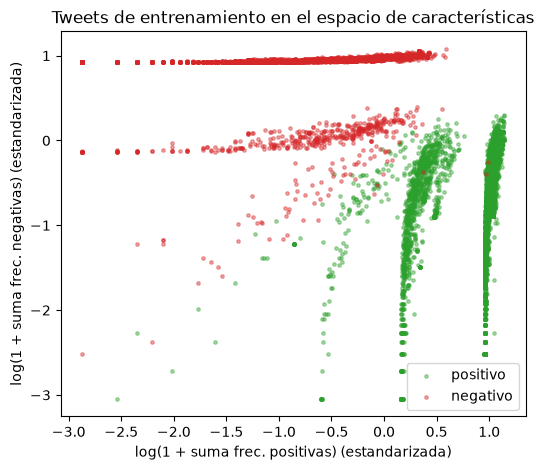

In [9]:
plt.figure(figsize=(6, 5))
for clase, color, nombre in [(1, "tab:green", "positivo"), (0, "tab:red", "negativo")]:
    m = y_train == clase
    plt.scatter(X_train[m, 1], X_train[m, 2], s=6, alpha=0.4, c=color, label=nombre)
plt.xlabel("log(1 + suma frec. positivas) (estandarizada)")
plt.ylabel("log(1 + suma frec. negativas) (estandarizada)")
plt.title("Tweets de entrenamiento en el espacio de características")
plt.legend()
plt.show()

Las dos clases quedan bastante bien separadas incluso en este espacio de solo dos dimensiones. Una frontera lineal debería funcionar.

<a id="modelo-de-regresion-logistica"></a>
<h2 style="color: #007ACC;">Modelo de regresión logística</h2>

La **regresión logística** modela la probabilidad de la clase positiva aplicando la función **sigmoide** a una combinación lineal de las características:

$$h_{\boldsymbol\theta}(\mathbf{x}) = \sigma(\boldsymbol\theta^\top \mathbf{x}) = \frac{1}{1 + e^{-\boldsymbol\theta^\top \mathbf{x}}} = P(y = 1 \mid \mathbf{x})$$

Predecimos positivo si $h_{\boldsymbol\theta}(\mathbf{x}) \geq 0.5$, es decir, si $\boldsymbol\theta^\top \mathbf{x} \geq 0$. La **frontera de decisión** es el hiperplano $\boldsymbol\theta^\top \mathbf{x} = 0$.

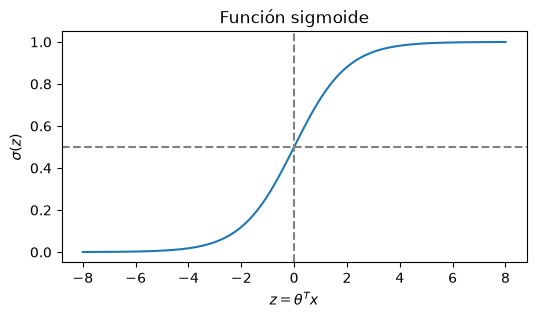

In [10]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))


z = np.linspace(-8, 8, 200)
plt.figure(figsize=(6, 3))
plt.plot(z, sigmoide(z))
plt.axhline(0.5, ls="--", c="gray")
plt.axvline(0, ls="--", c="gray")
plt.xlabel(r"$z = \theta^T x$")
plt.ylabel(r"$\sigma(z)$")
plt.title("Función sigmoide")
plt.show()

Para ajustar $\boldsymbol\theta$ minimizamos la **entropía cruzada binaria** (log-loss) sobre los $m$ ejemplos de entrenamiento:

$$J(\boldsymbol\theta) = -\frac{1}{m} \sum_{i=1}^{m} \left[ y^{(i)} \log h_{\boldsymbol\theta}(\mathbf{x}^{(i)}) + (1 - y^{(i)}) \log \left(1 - h_{\boldsymbol\theta}(\mathbf{x}^{(i)})\right) \right]$$

Esta función penaliza fuertemente las predicciones seguras y equivocadas: si $y = 1$ y el modelo predice $h \approx 0$, el término $-\log h$ tiende a infinito. Además es **convexa** en $\boldsymbol\theta$, así que el descenso del gradiente encuentra el mínimo global.

Su gradiente tiene una forma muy compacta (en notación matricial, con $\mathbf{X} \in \mathbb{R}^{m \times n}$):

$$\nabla_{\boldsymbol\theta} J = \frac{1}{m} \mathbf{X}^\top \left( \sigma(\mathbf{X}\boldsymbol\theta) - \mathbf{y} \right)$$

<a id="entrenamiento-con-descenso-del-gradiente"></a>
<h2 style="color: #007ACC;">Entrenamiento con descenso del gradiente</h2>

El **descenso del gradiente** actualiza los parámetros en la dirección opuesta al gradiente, con una tasa de aprendizaje $\alpha$:

$$\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha \nabla_{\boldsymbol\theta} J(\boldsymbol\theta)$$

Parámetros aprendidos (sesgo, peso_pos, peso_neg): [-0.383  4.155 -4.282]


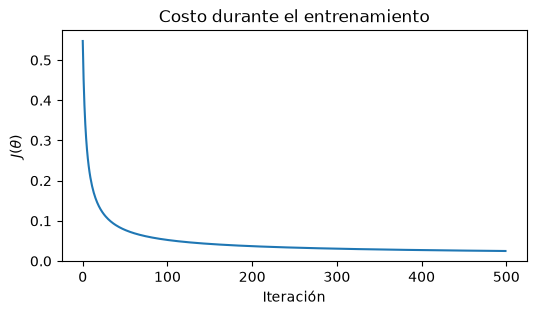

In [11]:
def costo(X, y, theta, eps=1e-12):
    h = sigmoide(X @ theta)
    return -np.mean(y * np.log(h + eps) + (1 - y) * np.log(1 - h + eps))


def descenso_gradiente(X, y, alpha=0.1, n_iter=1000):
    theta = np.zeros(X.shape[1])
    historial = []
    for _ in range(n_iter):
        gradiente = X.T @ (sigmoide(X @ theta) - y) / len(y)
        theta -= alpha * gradiente
        historial.append(costo(X, y, theta))
    return theta, historial


theta, historial = descenso_gradiente(X_train, y_train, alpha=0.5, n_iter=500)
print("Parámetros aprendidos (sesgo, peso_pos, peso_neg):", np.round(theta, 3))

plt.figure(figsize=(6, 3))
plt.plot(historial)
plt.xlabel("Iteración")
plt.ylabel(r"$J(\theta)$")
plt.title("Costo durante el entrenamiento")
plt.show()

El peso de la característica positiva es positivo y el de la negativa es negativo, como esperábamos. Dibujemos la frontera de decisión $\theta_0 + \theta_1 x_1 + \theta_2 x_2 = 0 \Rightarrow x_2 = -(\theta_0 + \theta_1 x_1) / \theta_2$:

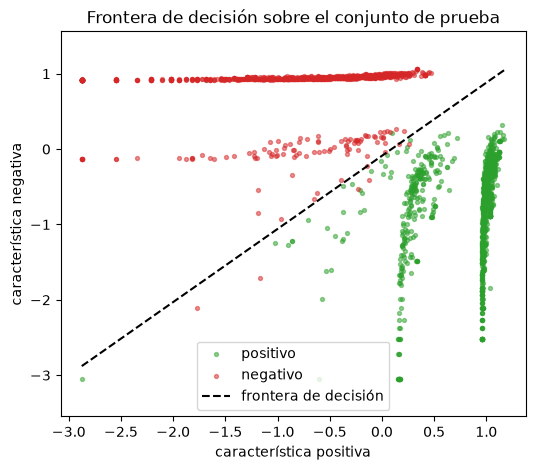

In [12]:
plt.figure(figsize=(6, 5))
for clase, color, nombre in [(1, "tab:green", "positivo"), (0, "tab:red", "negativo")]:
    m = y_test == clase
    plt.scatter(X_test[m, 1], X_test[m, 2], s=8, alpha=0.5, c=color, label=nombre)
x1 = np.linspace(X_test[:, 1].min(), X_test[:, 1].max(), 100)
plt.plot(x1, -(theta[0] + theta[1] * x1) / theta[2], "k--", label="frontera de decisión")
plt.ylim(X_test[:, 2].min() - 0.5, X_test[:, 2].max() + 0.5)
plt.xlabel("característica positiva")
plt.ylabel("característica negativa")
plt.title("Frontera de decisión sobre el conjunto de prueba")
plt.legend()
plt.show()

<a id="evaluacion"></a>
<h2 style="color: #007ACC;">Evaluación</h2>

Evaluamos sobre el conjunto de prueba. Además de la **exactitud** reportamos precisión, *recall* y F1 por clase, y la matriz de confusión.

Exactitud en prueba: 0.9965

              precision    recall  f1-score   support

    negativo       1.00      0.99      1.00      1000
    positivo       1.00      1.00      1.00      1000

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



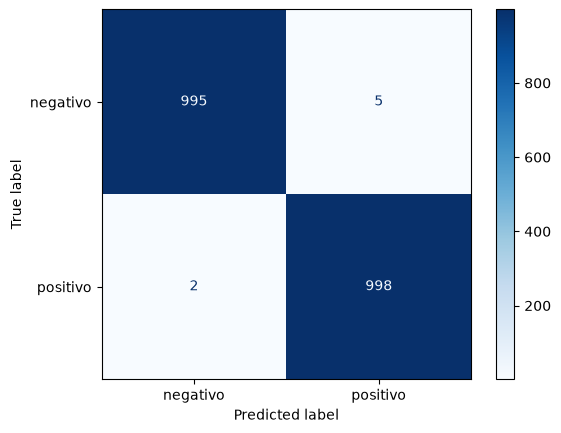

In [13]:
def predecir(X, theta):
    return (sigmoide(X @ theta) >= 0.5).astype(int)


y_pred = predecir(X_test, theta)
print(f"Exactitud en prueba: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["negativo", "positivo"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["negativo", "positivo"], cmap="Blues")
plt.show()

Con solo **tres números por tweet** el modelo clasifica casi perfectamente. ¿Demasiado bueno para ser cierto? Lo investigaremos en el análisis de errores. Primero, probemos con frases nuevas:

In [14]:
def sentimiento(texto):
    f = np.log1p(extraer_caracteristicas(procesar_tweet(texto), freqs))
    x = agregar_sesgo(((f - media) / desv).reshape(1, -1))
    p = sigmoide(x @ theta)[0]
    return f"{p:.3f} -> {'positivo' if p >= 0.5 else 'negativo'}"


for frase in ["I love this course, thank you!", "This is the worst day ever :(",
              "I am so happy and excited", "I miss you so much", "The movie was not good"]:
    print(f"{frase:<35} {sentimiento(frase)}")

I love this course, thank you!      0.955 -> positivo
This is the worst day ever :(       0.004 -> negativo
I am so happy and excited           0.990 -> positivo
I miss you so much                  0.095 -> negativo
The movie was not good              0.883 -> positivo


Fíjate en la última frase: *"The movie was not good"* se clasifica como **positiva**. El modelo ve *good* y no entiende que *not* la niega. Volveremos sobre este tipo de error más adelante.

<a id="regresion-logistica-con-scikit-learn"></a>
<h2 style="color: #007ACC;">Regresión logística con scikit-learn</h2>

En la práctica usaremos implementaciones optimizadas. `scikit-learn` permite encadenar la vectorización y el modelo en un `Pipeline`. Esta vez usaremos una representación mucho más rica: **TF-IDF**, un vector con una dimensión por palabra del vocabulario (la estudiaremos en detalle en el cuaderno 05).

`LogisticRegression` incluye **regularización L2** por defecto (hiperparámetro `C`, el inverso de la fuerza de regularización), importante cuando hay miles de características.

In [15]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

modelo_sk = make_pipeline(
    # Le pasamos nuestro propio tokenizador; desactivamos el preprocesamiento interno
    TfidfVectorizer(tokenizer=procesar_tweet, lowercase=False, token_pattern=None, min_df=2),
    LogisticRegression(C=1.0, max_iter=1000),
)
modelo_sk.fit(X_train_txt, y_train)

y_pred_sk = modelo_sk.predict(X_test_txt)
print(f"Exactitud (TF-IDF + scikit-learn): {accuracy_score(y_test, y_pred_sk):.4f}")
print(f"Tamaño del vocabulario: {len(modelo_sk[0].vocabulary_)}")

Exactitud (TF-IDF + scikit-learn): 0.9975
Tamaño del vocabulario: 3431


Una ventaja de los modelos lineales es su **interpretabilidad**: cada palabra tiene un peso. Los pesos más positivos y más negativos muestran qué palabras empujan la predicción hacia cada clase.

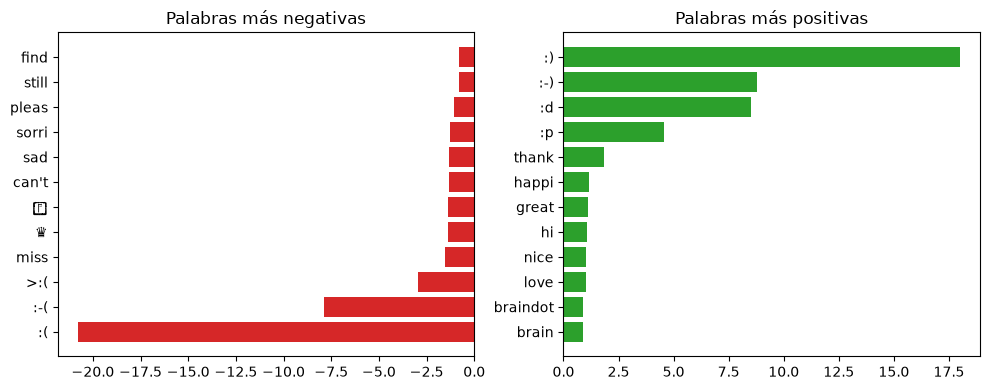

In [16]:
vocabulario = modelo_sk[0].get_feature_names_out()
pesos = modelo_sk[1].coef_[0]
orden = np.argsort(pesos)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].barh(vocabulario[orden[:12]], pesos[orden[:12]], color="tab:red")
axes[0].set_title("Palabras más negativas")
axes[1].barh(vocabulario[orden[-12:]], pesos[orden[-12:]], color="tab:green")
axes[1].set_title("Palabras más positivas")
plt.tight_layout()
plt.show()

<a id="analisis-de-errores"></a>
<h2 style="color: #007ACC;">Análisis de errores</h2>

Los emoticones dominan la lista de palabras más influyentes. Esto tiene una explicación: el corpus `twitter_samples` se construyó **etiquetando automáticamente los tweets según los emoticones que contenían**. Es decir, la etiqueta se deriva de una característica de entrada. El modelo aprende la regla de etiquetado, no el sentimiento.

¿Cuánto rinde el modelo si eliminamos los emoticones? Repitamos el experimento quitando todos los tokens que no contienen letras.

In [17]:
def procesar_sin_emoticones(tweet):
    return [t for t in procesar_tweet(tweet) if re.search(r"[a-z]", t)]


modelo_sin_emo = make_pipeline(
    TfidfVectorizer(tokenizer=procesar_sin_emoticones, lowercase=False, token_pattern=None, min_df=2),
    LogisticRegression(C=1.0, max_iter=1000),
)
modelo_sin_emo.fit(X_train_txt, y_train)
print(f"Exactitud SIN emoticones: {accuracy_score(y_test, modelo_sin_emo.predict(X_test_txt)):.4f}")

Exactitud SIN emoticones: 0.7655


La exactitud cae notablemente: esa es una estimación más honesta de la capacidad del modelo para reconocer **sentimiento a partir de las palabras**. Lección general: **una métrica muy alta merece sospecha**. Siempre hay que entender cómo se construyeron las etiquetas.

Veamos ahora algunos errores del modelo sin emoticones:

In [18]:
probs = modelo_sin_emo.predict_proba(X_test_txt)[:, 1]
errores = np.where((probs >= 0.5) != y_test)[0]
# Los errores más "seguros": probabilidad lejos de 0.5
peores = errores[np.argsort(-np.abs(probs[errores] - 0.5))][:8]

pd.set_option("display.max_colwidth", 120)
pd.DataFrame({
    "tweet": [X_test_txt[i] for i in peores],
    "real": ["positivo" if y_test[i] else "negativo" for i in peores],
    "P(positivo)": probs[peores].round(3),
})

,tweet,real,P(positivo)
0,#@TheWineSociety: .@Vin_dourthe will be very pleased to here it! :)… http://t.co/i9zotnyyec,positivo,0.014
1,@JackJackJohnson please put it on spotify too please? :),positivo,0.035
2,@machado_man4 @TashaShukla @CloydRivers and freedom to hangout with whoever you want to!!!!!!!!! :),positivo,0.080
3,Remember that one time I didn't go to flume/kaytranada/alunageorge even though I had tickets? I still want to kms. :...,positivo,0.087
4,@imdanielpadilla hi!!!!!! love u :( :(,negativo,0.899
5,"don't cry hakhakhak :))""@ksdahyun: T_____________T https://t.co/KKbgfmYEgO""",positivo,0.107
6,if only you knew that the whole class was crying because of your hurtful words. :),positivo,0.116
7,@tayser1989 please I can't sleep till you broadcast I needa laugh a little !:),positivo,0.117


Los errores típicos de un modelo de **bolsa de palabras** incluyen:

- **Negaciones:** *"not happy"* contiene *happy*, una palabra positiva. El modelo no sabe que *not* invierte su sentido.
- **Ironía y sarcasmo:** *"Great, another Monday"*.
- **Etiquetas ruidosas:** tweets cuyo texto no expresa el sentimiento de su etiqueta (recuerda que se etiquetaron por emoticones).
- **Palabras raras o fuera del vocabulario.**

Estos problemas motivan modelos que consideran **el orden y el contexto** de las palabras: N-gramas (módulo 2), redes recurrentes (módulo 3) y Transformers (módulo 4). En el siguiente cuaderno resolveremos la misma tarea con un enfoque probabilístico: **Naive Bayes**.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Vajjala, S., Majumder, B., Gupta, A. & Surana, H. (2020). *Practical Natural Language Processing*. O'Reilly Media.
- Documentación de scikit-learn: *Working With Text Data*. [scikit-learn.org](https://scikit-learn.org/stable/tutorial/text_analytics/working_with_text_data.html)
- Go, A., Bhayani, R. & Huang, L. (2009). Twitter Sentiment Classification using Distant Supervision. *CS224N Project Report*, Stanford.